# Hyperparameter robustness at $L=12$

The wall-clock figures compare each method **at one setting of its own knob**.
A referee is entitled to ask whether those settings were chosen fairly, and for
the regularised Newton rules they matter enormously: the Toffoli at an initial
spread of $0.01\pi$ is not solved by `NewtonTRM(delta=0.5)` in 200 iterations,
and is solved in 92 by `NewtonTRM(delta=1e-4)`.

This notebook makes that a measurement rather than an anecdote. The claim being
tested is not "GEOPE is faster" but

> GEOPE solves the problem at every spread with one fixed set of
> hyperparameters, while each *regularised* GRAPE rule has a working window
> that is narrow and **moves with the conditioning**.

So the methods split in two, and the split is the result:

**Fixed, not searched.** GEOPE's step size is $t_{\max}=1$ on geometric grounds:
the line search minimises the geodesic *distance* to the target, so $t=1$ is the
whole step along that geodesic and $[-1,0]$ is the natural bracket. There is no
regularisation parameter because there is no Hessian to regularise.
`NewtonSaddleFree` is in the same position for a different reason — its `rcond`
is the float64 relative cutoff separating a numerically nonzero eigenvalue from
noise, the same $10^{-8}$ a pseudo-inverse uses, and it is a statement about
double precision rather than about this problem.

**Searched.** `NewtonTRM`, `NewtonRFO` and `LBFGS` each have a genuine knob,
swept over the decades either side of its default at four initial spreads.

Both fixed methods are still *checked* — GEOPE across the Armijo family of
line searches, saddle-free across six decades of `rcond` — because "there is
nothing to tune" is a claim that deserves evidence rather than assertion. Those
results are reported as tables, not as windows.

Everything is cached per block, so re-running is free and raising `N_RUNS`
extends the blocks rather than invalidating them.

In [1]:
from common import *

#: The pulse length the whole grid is run at -- the small case, so it is affordable.
L_STEPS = 12
N_RUNS = 10

#: The conditioning knob. At $1.0\pi$ the Hessian is ~1e4 conditioned at the start and
#: every method works; at $0.01\pi$ it is ~1e6 and most do not.
SPREADS = (0.01, 0.1, 0.5, 1.0)
SPREADS_LABELS=(r"\pi/100", r"\pi/10", r"\pi/2", r"\pi")
#: Fixed by double precision, not searched: the same relative cutoff a pseudo-inverse
#: uses to call an eigenvalue numerically zero.
SADDLE_FREE_RCOND = 1e-8

#: `3`, `MAX_STEPS`, `PRECISION` and `GEOPE_MAX_STEP` come from `common`, which
#: carries the same values every other notebook uses.
print(f"cache   {CACHE_DIR.resolve()}")
print(f"figures {FIGURE_DIR.resolve()}")
print(f"{3} qubits, L = {L_STEPS}, {N_RUNS} seeds, spreads {SPREADS}")

cache   /Users/rwiersema/Documents/geope/review_final/cache
figures /Users/rwiersema/Documents/geope/review_final/figures
3 qubits, L = 12, 10 seeds, spreads (0.01, 0.1, 0.5, 1.0)


## One trial

A trial is one seed at one setting, reduced to three numbers: the infidelity it
reached, the iterations it took and the wall clock it spent. The trajectory
itself is *not* stored — there are well over a hundred blocks here rather than
Figure 1's ten, and the summary is all the robustness plot reads.

## The cache

One block per setting, keyed by the sha1 of the whole config dict — the knob's
*name* and value included, so nothing collides and a block is identifiable on
disk without opening its sidecar. Blocks are extended rather than replaced, so
raising `N_RUNS` computes only the new seeds, and each seed is written as it
lands so an interrupted sweep resumes where it stopped.

The per-seed timing, the model and the slugs all come from `common.py`; what is local here is the block's config and the three arrays it stores.

In [2]:
def block_config(method, knob, value, spread, config):
    """Everything that changes this block's numbers.

    The method, the knob value and the spread are all in the *tag* as well as in the
    config, so the cache is browsable: one folder per method, one file per setting,
    the spread on the end. Do not add keys -- the digest is the cache key, and the
    blocks on disk took fourteen hours.
    """
    return {
        "tag": f"hyper_CCX_L{L_STEPS}_{method}_{knob}{value_slug(value)}"
               f"_{spread_slug(spread)}",
        "kind": "hyperparameter-search",
        "gate": "CCX",
        "steps": L_STEPS,
        "method": method,
        "knob": knob,
        "value": value if isinstance(value, str) else float(value),
        "spread": float(spread),
        "config": repr(config),
        "n_qubits": 3,
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
    }


def load_trials(npz_path):
    """The seeds already stored, or ``None`` if the block is absent."""
    stored = cache_load(npz_path)
    if stored is None:
        return None
    return (
        list(stored["infidelities"]),
        list(stored["steps"]),
        list(stored["seconds"]),
    )


def save_trials(npz_path, json_path, cfg, infidelities, steps, seconds):
    """Write the block plus a readable sidecar of its config."""
    cache_save(
        npz_path,
        json_path,
        cfg,
        {
            "infidelities": np.asarray(infidelities, dtype=float),
            "steps": np.asarray(steps, dtype=int),
            "seconds": np.asarray(seconds, dtype=float),
        },
        n_runs=len(infidelities),
    )


def run_trials(cfg, build, n_runs, *, force=False, verbose=True, prefix=""):
    """Every seed of one block, reading and extending the cache.

    Args:
        cfg: The block's config; its digest is the cache key.
        build: ``() -> (params, optimiser, config, spread)``, called only on a miss so
            a fully cached sweep never touches JAX.
        n_runs: How many seeds are wanted.
        force: Recompute from seed 0, discarding what is stored.
        verbose: Print one line as the block lands.
        prefix: Progress counter to print ahead of that line.

    Returns:
        ``(infidelities, steps, seconds)``, each a list of ``n_runs`` values.
    """
    npz_path, json_path = block_paths(cfg)
    cached = None if force else load_trials(npz_path)
    infidelities, steps, seconds = cached if cached else ([], [], [])
    have = len(infidelities)

    if have >= n_runs:
        note = f"cached ({have} stored)"
    else:
        params, optimiser, config, spread = build()
        # Seed 10_000 is outside the run range, so the warm-up never doubles as a
        # real sample.
        warm_up(
            optimiser,
            random_pulse(params, np.random.default_rng(10_000), spread),
            config,
        )
        started = time.perf_counter()
        for seed in range(have, n_runs):
            pulse = random_pulse(params, np.random.default_rng(seed), spread)
            infidelity, used, elapsed = timed_trial(optimiser, pulse, config)
            infidelities.append(infidelity)
            steps.append(used)
            seconds.append(elapsed)
            # Written every seed, not once at the end: `NewtonRFO` at a small kappa
            # is minutes per block, and an interrupted sweep should not lose them.
            save_trials(npz_path, json_path, cfg, infidelities, steps, seconds)
        note = f"computed {n_runs - have} in {time.perf_counter() - started:5.0f}s"

    reached = int(np.sum(np.asarray(infidelities[:n_runs]) < 1.0 - PRECISION))
    if verbose:
        print(
            f"  {prefix}{cfg['tag']:54s} {reached:2d}/{n_runs}  "
            f"median 1-F {np.median(infidelities[:n_runs]):.1e}  "
            f"median {np.median(steps[:n_runs]):3.0f} steps   {note}",
            flush=True,
        )
    return infidelities[:n_runs], steps[:n_runs], seconds[:n_runs]

## The grid

One knob per searched rule, and in each case *the* knob — the one that decides
what is done with a Hessian that is both indefinite and ill-conditioned:

| rule | knob | what it controls |
|---|---|---|
| `NewtonTRM` | `delta` | the floor the spectrum is **shifted** to |
| `NewtonRFO` | `kappa` | the condition number `condition_loop` scales down to |
| `LBFGS` | `memory` | how many curvature pairs the implicit inverse Hessian spans |

Each grid straddles the library default by several decades; `DEFAULTS` records
where that default sits and the figure marks it.

`CHECKS` holds the two fixed methods' settings. They are run over a range too,
but the range is there to *support* the claim that the value does not matter,
so the results go in a table rather than in the window analysis.

In [3]:
#: ``knob`` names the argument, ``axis`` labels it, ``build`` turns a value into
#: the config `dispatch` expects.
SEARCH = {
    "NewtonTRM": dict(
        knob="delta",
        axis=r"Spectrum floor $\delta$",
        values=(1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0),
        build=lambda v: NewtonTRM(delta=float(v)),
    ),
    "NewtonRFO": dict(
        knob="kappa",
        axis=r"Condition target $\kappa$",
        values=(1e2, 1e3, 1e4, 1e5, 1e6, 1e8, 1e10, 1e12),
        build=lambda v: NewtonRFO(kappa=float(v)),
    ),
    "LBFGS": dict(
        knob="memory",
        axis=r"Curvature pairs $r$",
        values=(2, 5, 10, 25, 50, 100),
        build=lambda v: LBFGS(int(v)),
    ),
}

#: Where the library's own default sits, for the marker in the figure.
DEFAULTS = {"NewtonTRM": 0.1, "NewtonRFO": 100.0, "LBFGS": 10}

#: The two hyperparameter-free methods, and the settings each is checked over.
#: ``reference`` is the one the figure draws; it heads each list.
CHECKS = {
    "GEOPE": dict(
        knob="line_search",
        reference="Armijo",
        settings={
            "Armijo": (Armijo(), GEOPE_MAX_STEP),
            "QuadraticArmijo": (QuadraticArmijo(), GEOPE_MAX_STEP),
            "ApproximateQuadraticArmijo": (
                ApproximateQuadraticArmijo(),
                GEOPE_MAX_STEP,
            ),
        },
    ),
    "NewtonSaddleFree": dict(
        knob="rcond",
        reference="1e-08",
        settings={
            f"{v:g}": NewtonSaddleFree(rcond=float(v))
            for v in (SADDLE_FREE_RCOND, 1e-14, 1e-12, 1e-10, 1e-6, 1e-4, 1e-2)
        },
    ),
}

searched = sum(len(s["values"]) for s in SEARCH.values()) * len(SPREADS)
checked = sum(len(c["settings"]) for c in CHECKS.values()) * len(SPREADS)
print(f"{searched} searched + {checked} checked blocks x {N_RUNS} seeds")

92 searched + 40 checked blocks x 10 seeds


## The sweep

`NewtonRFO` at $\kappa=10^2$ is the expensive corner — `condition_loop`
re-diagonalises the augmented Hessian until the target is met, which is tens of
`eigvalsh` calls per step — so the fixed methods are swept first and the
progress counter is worth watching the first time through. Everything after that
is a cache read.

In [4]:
def block_config(method, knob, value, spread, config):
    """Everything that changes this block's numbers.

    The method, the knob value and the spread are all in the *tag* as well as in
    the config, so the cache is browsable: one folder per method, one file per
    setting, the spread on the end.
    """
    return {
        "tag": f"hyper_CCX_L{L_STEPS}_{method}_{knob}{value_slug(value)}"
               f"_{spread_slug(spread)}",
        "kind": "hyperparameter-search",
        "gate": "CCX",
        "steps": L_STEPS,
        "method": method,
        "knob": knob,
        "value": value if isinstance(value, str) else float(value),
        "spread": float(spread),
        "config": repr(config),
        "n_qubits": 3,
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
    }


def summarise(rows, method, knob, value, spread, infidelities, steps, seconds):
    """Append one tidy row; shared so both sweeps report identically."""
    infidelities = np.asarray(infidelities)
    rows.append(
        {
            "method": method,
            "knob": knob,
            "value": value,
            "spread": float(spread),
            "converged": float(np.mean(infidelities < 1.0 - PRECISION)),
            "infidelity": float(np.median(infidelities)),
            "steps": float(np.median(steps)),
            "seconds": float(np.median(seconds)),
        }
    )


def _run(method, knob, value, spread, config, n_runs, force, verbose, prefix, rows):
    """One block: build lazily, run or read, and append its tidy row."""

    def build():
        params = make_parameters(3, L_STEPS, "CCX", spread=spread)
        optimiser = (
            Geope(params, history=History())
            if method == "GEOPE"
            else Grape(params, precision=PRECISION, history=History())
        )
        return params, optimiser, config, spread

    block = run_trials(
        block_config(method, knob, value, spread, config),
        build, n_runs, force=force, verbose=verbose, prefix=prefix,
    )
    summarise(rows, method, knob, value, spread, *block)


def hyper_sweep(n_runs=None, force=False, verbose=True):
    """Every block.

    Returns:
        ``(searched, checked)`` frames. They are kept apart because their
        ``value`` columns are different kinds of thing: a float on a log axis
        for the searched rules, a setting *name* for the checked ones.
    """
    n_runs = N_RUNS if n_runs is None else n_runs
    total = (
        sum(len(s["values"]) for s in SEARCH.values())
        + sum(len(c["settings"]) for c in CHECKS.values())
    ) * len(SPREADS)
    searched_rows, checked_rows, done, started = [], [], 0, time.perf_counter()

    # The fixed methods first: they are seconds a block, and having the
    # reference in hand makes the long RFO wait afterwards readable.
    for method, check in CHECKS.items():
        for name, config in check["settings"].items():
            for spread in SPREADS:
                done += 1
                _run(method, check["knob"], name, spread, config, n_runs,
                     force, verbose, f"[{done:3d}/{total}] ", checked_rows)

    for method, spec in SEARCH.items():
        for value in spec["values"]:
            for spread in SPREADS:
                done += 1
                _run(method, spec["knob"], float(value), spread,
                     spec["build"](value), n_runs, force, verbose,
                     f"[{done:3d}/{total}] ", searched_rows)

    if verbose:
        print(f"\n{total} blocks in {time.perf_counter() - started:.0f}s")
    return pd.DataFrame(searched_rows), pd.DataFrame(checked_rows)


hyper_df, checked_df = hyper_sweep()

  [  1/132] hyper_CCX_L12_GEOPE_line_searchArmijo_spread0p01pi     10/10  median 1-F 2.8e-10  median  48 steps   cached (10 stored)
  [  2/132] hyper_CCX_L12_GEOPE_line_searchArmijo_spread0p1pi      10/10  median 1-F 1.4e-10  median  52 steps   cached (10 stored)
  [  3/132] hyper_CCX_L12_GEOPE_line_searchArmijo_spread0p5pi      10/10  median 1-F 3.5e-10  median  38 steps   cached (10 stored)
  [  4/132] hyper_CCX_L12_GEOPE_line_searchArmijo_spread1pi        10/10  median 1-F 1.4e-10  median  38 steps   cached (10 stored)
  [  5/132] hyper_CCX_L12_GEOPE_line_searchQuadraticArmijo_spread0p01pi 10/10  median 1-F 1.1e-12  median  44 steps   cached (10 stored)
  [  6/132] hyper_CCX_L12_GEOPE_line_searchQuadraticArmijo_spread0p1pi 10/10  median 1-F 1.6e-13  median  50 steps   cached (10 stored)
  [  7/132] hyper_CCX_L12_GEOPE_line_searchQuadraticArmijo_spread0p5pi 10/10  median 1-F 3.7e-15  median  34 steps   cached (10 stored)
  [  8/132] hyper_CCX_L12_GEOPE_line_searchQuadraticArmijo_spre

## The two methods with nothing to tune

Before the search, the reference. If any cell here falls short of $10/10$ the
rest of the notebook has no claim to make.

GEOPE is checked across the Armijo family of line searches, at the fixed
$t_{\max}=1$. `NewtonSaddleFree` is checked across six decades of `rcond`,
which is the sharper test of the two: it says the truncation cutoff can be
wrong by orders of magnitude and the method still lands, whereas a *shift*
of the same spectrum cannot.

In [5]:
def check_table(method):
    """Converged fraction and median iterations, settings x spreads."""
    rows = checked_df[checked_df["method"] == method]
    fraction = rows.pivot(index="value", columns="spread", values="converged")
    iterations = rows.pivot(index="value", columns="spread", values="steps")
    order = list(CHECKS[method]["settings"])
    width = max(len(name) for name in order) + 2
    print(f"{LABELS[method]}  ({CHECKS[method]['knob']})")
    print(" " * width + "fraction converged" + " " * 12 + "median iterations")
    print(" " * width + "".join(f"{s:>7g}" for s in SPREADS)
          + "   " + "".join(f"{s:>7g}" for s in SPREADS))
    for name in order:
        print(
            f"{name:{width}s}"
            + "".join(f"{fraction.loc[name, s]:7.1f}" for s in SPREADS)
            + "   "
            + "".join(f"{iterations.loc[name, s]:7.0f}" for s in SPREADS)
        )
    print()


for method in CHECKS:
    check_table(method)

#: The reference curves the searched panels are drawn against.
REFERENCES = {
    method: checked_df[
        (checked_df["method"] == method)
        & (checked_df["value"] == check["reference"])
    ].set_index("spread")
    for method, check in CHECKS.items()
}

GEOPE  (line_search)
                            fraction converged            median iterations
                               0.01    0.1    0.5      1      0.01    0.1    0.5      1
Armijo                          1.0    1.0    1.0    1.0        48     52     38     38
QuadraticArmijo                 1.0    1.0    1.0    1.0        44     50     34     33
ApproximateQuadraticArmijo      1.0    1.0    1.0    1.0        44     50     34     33

Newton: SFN  (rcond)
        fraction converged            median iterations
           0.01    0.1    0.5      1      0.01    0.1    0.5      1
1e-08       1.0    1.0    1.0    1.0        40     36     42     40
1e-14       1.0    1.0    1.0    1.0        52     48     42     40
1e-12       1.0    1.0    1.0    1.0        52     46     42     40
1e-10       1.0    1.0    1.0    1.0        45     42     42     40
1e-06       0.8    1.0    1.0    1.0        24     21     34     35
0.0001      0.8    0.9    1.0    1.0        12     14     21     

## The robust window, and the re-tuning cost

Two numbers for each searched rule, and the second is the one the argument
rests on.

**Robust window** — the knob values that reach the target on every seed at
*every* spread. Width alone is a weak claim, though: a knob can fail across the
board for reasons that have nothing to do with conditioning.

**Re-tuning cost** — of the settings that work at the easy spread $1.0\pi$, how
many *stop* working at the hard one $0.01\pi$. This is what separates "wide
window" from "window in a fixed place": a rule scoring zero here can be tuned
once on an easy instance and then left alone, while a rule scoring high has to
be re-tuned whenever the conditioning changes. Both fixed methods score zero
trivially, having nothing to tune.

In [6]:
def window_summary(frame, method):
    """``(robust, grid, works_easy, lost)`` for one rule.

    ``robust`` is the values converging on every seed at every spread;
    ``works_easy`` those converging at the widest spread; ``lost`` the subset of
    *those* that fail at the narrowest one — the settings a tuning run on an
    easy instance would have handed you, that the hard instance then breaks.
    """
    rows = frame[frame["method"] == method]
    grid = sorted(rows["value"].unique())
    worst = rows.groupby("value")["converged"].min()
    robust = [v for v in grid if worst[v] >= 1.0]

    def converging(spread):
        at = rows[rows["spread"] == spread].set_index("value")["converged"]
        return {v for v in grid if at.get(v, 0.0) >= 1.0}

    easy, hard = converging(max(SPREADS)), converging(min(SPREADS))
    return robust, grid, sorted(easy), sorted(easy - hard)


print(f"{'rule':22s} {'robust':>9s}  {'window':>16s}   "
      f"{'works at 1pi':>12s}  {'lost at 0.01pi':>14s}")
for method in SEARCH:
    robust, grid, easy, lost = window_summary(hyper_df, method)
    span = f"{min(robust):g} - {max(robust):g}" if robust else "(none)"
    print(f"{LABELS[method]:22s} {len(robust):4d}/{len(grid):-4d}  {span:>16s}   "
          f"{len(easy):12d}  {len(lost):14d}"
          + (f"   {[f'{v:g}' for v in lost]}" if lost else ""))
for method in CHECKS:
    n = len(CHECKS[method]["settings"])
    print(f"{LABELS[method]:22s} {n:4d}/{n:-4d}  {'(no knob)':>16s}   "
          f"{n:12d}  {0:14d}")

rule                      robust            window   works at 1pi  lost at 0.01pi
Newton: TRM               0/   9            (none)              6               3   ['1e-06', '0.001', '0.1']
Newton: RFO               5/   8      1000 - 1e+08              8               3   ['100', '1e+10', '1e+12']
L-BFGS                    2/   6          50 - 100              6               4   ['2', '5', '10', '25']
GEOPE                     3/   3         (no knob)              3               0
Newton: SFN               7/   7         (no knob)              7               0


## Figure — one knob, four spreads

Three rows, read as cost, reliability, accuracy. **Top row**: the median
iterations to reach $1-F<10^{-9}$. **Middle row**: the fraction of seeds that
reach it within 200 iterations. **Bottom row**: the median infidelity actually
reached, with the target as a dotted line. The vertical grey line is the
library default; the horizontal bands are the two hyperparameter-free methods,
spanning the range they cover across all four spreads.

The top row's median is taken over all ten seeds and is **censored at the
200-iteration budget**, drawn as the dotted ceiling: a curve sitting on it has
not converged rather than converged slowly, and the middle row says which. So
L-BFGS is flat on the ceiling at $0.01\pi$ for every memory size — it is not
uniformly slow there, it simply does not land.

Each searched panel has a window that narrows and *shifts* as the spread
shrinks. The cost row narrows it further: `NewtonTRM` converges on every seed
across $\delta\in[10^{-4},10^{-2}]$, but pays 76 iterations at one end of that
window and 33 at the other, and `NewtonRFO` is monotone in $\kappa$ at the
three wider spreads — the regularisation that buys robustness is bought back in
iterations. The bands do not move, because neither method has a setting that
the conditioning could invalidate; the top row is the one place they separate
rather than coincide, GEOPE landing in 13–24 iterations against saddle-free's
26–36.

figures/fig7_hyperparameter_robustness_L12.pdf


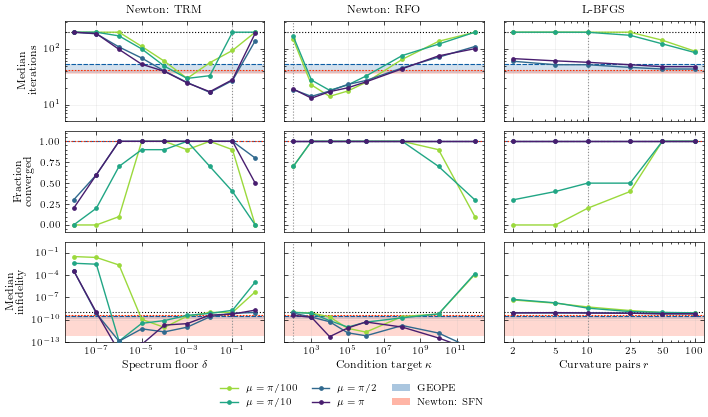

In [7]:
#: One colour per spread, ordered light to dark so the ranking reads off the
#: lines without consulting the legend.
SPREAD_COLOURS = dict(
    zip(SPREADS, plt.cm.viridis(np.linspace(0.85, 0.08, len(SPREADS))))
)
#: The two references. Distinct dash patterns as well as colours, because both
#: land on the target and their lines would otherwise sit exactly on top of
#: each other -- which is the result, but only if you can see both.
REFERENCE_STYLE = {
    "GEOPE": (COLOURS["GEOPE"], (0, (4, 1.4))),
    "NewtonSaddleFree": (COLOURS["NewtonSaddleFree"], (0, (1.4, 1.4))),
}
#: `memory` is six values over a decade and a half; left to itself a log axis
#: labels its minor ticks instead and the panel turns to mush.
EXPLICIT_TICKS = {"LBFGS": SEARCH["LBFGS"]["values"]}

methods = list(SEARCH)
# Three rows, read top to bottom as cost, then reliability, then accuracy: a
# setting can sit inside the robust window and still cost several times the
# iterations of its neighbour, which the lower two rows cannot show.
fig, axes = plt.subplots(
    3, len(methods), figsize=(TWO_COLUMN, 4.4), sharey="row",
    gridspec_kw=dict(wspace=0.10, hspace=0.10),
)

for column, method in enumerate(methods):
    spec = SEARCH[method]
    ax_it, ax_frac, ax_inf = (axes[row, column] for row in range(3))
    rows = hyper_df[hyper_df["method"] == method]

    # The references first, so the searched curves draw over them.
    for reference, frame in REFERENCES.items():
        colour, dashes = REFERENCE_STYLE[reference]
        band = frame["infidelity"]
        ax_inf.axhspan(band.min(), band.max(), color=colour, alpha=0.18, lw=0, zorder=1)
        ax_inf.axhline(band.max(), color=colour, ls=dashes, lw=0.8, zorder=2)
        # `max()` is the slowest of the four spreads, keeping the worst-case
        # convention the other two rows use. This is the one row where the two
        # bands separate rather than coincide: both land, at different prices.
        iterations = frame["steps"]
        ax_it.axhspan(
            iterations.min(), iterations.max(), color=colour, alpha=0.18, lw=0, zorder=1
        )
        ax_it.axhline(iterations.max(), color=colour, ls=dashes, lw=0.8, zorder=2)
        # Middle row: both are 1.0 at every spread, so the two lines coincide
        # and only the dash patterns tell them apart.
        ax_frac.axhline(
            frame["converged"].min(), color=colour, ls=dashes, lw=0.8, zorder=2
        )

    for spread in SPREADS:
        series = rows[rows["spread"] == spread].sort_values("value")
        style = dict(color=SPREAD_COLOURS[spread], marker="o", ms=2.4, lw=1.0, zorder=3)
        ax_it.plot(series["value"], series["steps"], **style)
        ax_frac.plot(series["value"], series["converged"], **style)
        ax_inf.plot(series["value"], series["infidelity"], **style)

    for ax in (ax_it, ax_frac, ax_inf):
        ax.set_xscale("log")
        ax.grid(alpha=0.25, which="major", lw=0.4)
        # Where the library -- and every other figure in the response -- sits,
        # so the reader can see whether the default is inside the window.
        ax.axvline(DEFAULTS[method], color="0.55", ls=":", lw=0.8, zorder=1)
        if method in EXPLICIT_TICKS:
            ax.set_xticks(EXPLICIT_TICKS[method])
            ax.set_xticklabels([f"{v:g}" for v in EXPLICIT_TICKS[method]])
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax_it.set_yscale("log")

    ax_it.axhline(MAX_STEPS, color="black", ls=":", lw=0.8, zorder=2)
    ax_inf.set_yscale("log")
    ax_inf.axhline(1.0 - PRECISION, color="black", ls=":", lw=0.8, zorder=2)
    ax_it.set_ylim(5, 320)
    ax_frac.set_ylim(-0.08, 1.12)
    ax_inf.set_ylim(1e-13, 3.0)

    for ax in (ax_it, ax_frac):
        ax.tick_params(axis="x", which="both", labelbottom=False)

    ax_it.yaxis.set_minor_formatter(NullFormatter())
    ax_it.set_title(LABELS[method])
    ax_inf.set_xlabel(spec["axis"])

axes[0, 0].set_ylabel("Median\n iterations")
axes[1, 0].set_ylabel("Fraction\nconverged")
axes[2, 0].set_ylabel("Median\ninfidelity")
handles = [
    Line2D([], [], color=SPREAD_COLOURS[spread], marker="o", ms=2.4, lw=1.0,
           label=rf"$\mu={label}$")
    for spread, label in zip(SPREADS, SPREADS_LABELS)
] + [
    Patch(facecolor=REFERENCE_STYLE[m][0], alpha=0.35,
          label=rf"{LABELS[m]}")
    for m in CHECKS
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.05), handlelength=1.8, columnspacing=1.6)
fig.subplots_adjust(left=0.095, right=0.995, top=0.95, bottom=0.22,
                    wspace=0.10, hspace=0.10)

print(save_figure(fig, f"fig7_hyperparameter_robustness_L{L_STEPS}"))
plt.show()